# 📘 5.2 Decision Tree Regression

### Learning piecewise engineering rules from data

Linear regression represents one global relationship across the feature domain.
Many engineering systems do not behave that way:

* pump efficiency changes across operating regions;
* heat-transfer behaviour can change after a flow transition;
* component wear may accelerate after a threshold;
* control logic may create distinct operating modes; and
* manufacturing processes may behave differently across machine settings.

A **decision tree regressor** learns a sequence of threshold rules and predicts a
constant value inside each final region. This makes the model easy to visualise,
but also creates important limitations: step-like predictions, weak extrapolation
and a strong tendency to overfit when the tree is allowed to grow without control.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain how a regression tree partitions a feature domain using threshold rules;
* fit a `DecisionTreeRegressor` and interpret its terminal-leaf predictions;
* visualise a small tree and connect its rules to a stepwise prediction curve;
* investigate `max_depth` and `min_samples_leaf` as complexity controls;
* distinguish training performance from validation performance;
* explain why a decision tree does not extrapolate a physical trend;
* build and visualise a tree with two engineering features; and
* interpret permutation importance without treating it as causality.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* scikit-learn — [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)
* scikit-learn — [Decision trees user guide](https://scikit-learn.org/stable/modules/tree.html)
* scikit-learn — [plot_tree](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html)
* scikit-learn — [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
* US Department of Energy — [Improving Pumping System Performance](https://www.energy.gov/sites/default/files/2014/05/f16/pump.pdf)


## 📂 5.2.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no
cell requires editing or typed input.

The Week 5 workbook will contain paired exploration and problem-solving activities
to begin in Monday's workshop, continue in Wednesday's practical, and complete
during revision.


### 📖 Core language for 5.2

Throughout this notebook:

* a **node** contains a subset of training samples;
* a **split** applies a rule such as `flow_rate <= 74`;
* a **branch** is one outcome of a split;
* a **leaf** or **terminal node** is a region where the tree makes a prediction;
* **depth** is the number of split levels from the root to a node;
* **impurity** measures target variation inside a node;
* **pruning or regularisation** limits tree complexity; and
* **piecewise constant** means the prediction is constant inside each leaf region.


## 📂 5.2.1 How does a regression tree make a prediction?

A regression tree repeatedly asks threshold questions. With one feature, a split
might be

$$
q \le 74\ \mathrm{m^3/h}.
$$

Samples satisfying the rule go left; the remaining samples go right. Splitting
continues until a stopping rule is reached.

With the default squared-error criterion, the prediction in a leaf is the mean
target value of the training samples that reach that leaf:

$$
\hat{y}_{\text{leaf}} = \frac{1}{n_{\text{leaf}}}
\sum_{i\in\text{leaf}} y_i.
$$

The algorithm chooses splits that reduce the weighted target variance in the child
nodes. The fitted function is therefore made from flat regions rather than a smooth
equation.


### ⚠️ Point of note

A tree rule is learned from the available data. A threshold is not automatically:

* a physical transition;
* a safety limit;
* a causal boundary; or
* a recommended operating set point.

Engineering interpretation and independent evidence remain necessary.


In [ ]:
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.precision", 4)


## 📂 5.2.2 Engineering example: centrifugal-pump efficiency

Centrifugal-pump performance is commonly described across a range of flow rates.
Efficiency normally rises toward a best-efficiency region and falls away from it.
Operating well away from the best efficiency point can increase energy use and
mechanical stress.

### ⚠️ Data note

The dataset below is synthetic and deterministic. Its curved efficiency profile is
inspired by the form of pump-performance curves discussed in the US Department of
Energy pumping-system sourcebook. It is not a manufacturer's certified pump curve
and must not be used for equipment selection.

We retain the noise-free teaching function only so we can inspect model behaviour.
In a real experiment, the true response would be unknown.


In [ ]:
rng = np.random.default_rng(5201)

flow_rate_m3h = np.linspace(20.0, 140.0, 49)
best_efficiency_flow_m3h = 85.0

true_efficiency_percent = (
    83.0
    - 0.012 * (flow_rate_m3h - best_efficiency_flow_m3h) ** 2
)
measured_efficiency_percent = (
    true_efficiency_percent
    + rng.normal(0.0, 1.6, size=flow_rate_m3h.size)
)

pump_data = pd.DataFrame({
    "flow_rate_m3h": flow_rate_m3h,
    "efficiency_percent": measured_efficiency_percent,
    "true_efficiency_for_teaching_only": true_efficiency_percent,
})

pump_data.head(8)


,flow_rate_m3h,efficiency_percent,true_efficiency_for_teaching_only
0,20.0,33.9367,32.300
1,22.5,34.5073,36.125
2,25.0,39.2568,39.800
3,27.5,41.5053,43.325
4,30.0,45.0848,46.700
5,32.5,51.6872,49.925
6,35.0,51.8612,53.000
7,37.5,59.7184,55.925


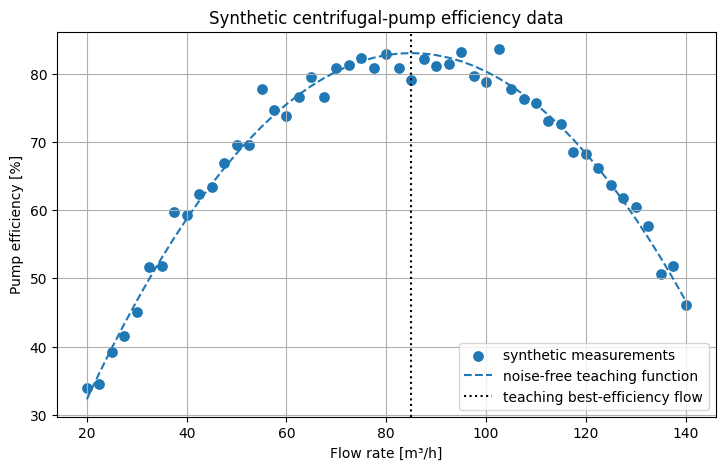

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5))

ax.scatter(
    pump_data["flow_rate_m3h"],
    pump_data["efficiency_percent"],
    s=45,
    label="synthetic measurements",
)
ax.plot(
    pump_data["flow_rate_m3h"],
    pump_data["true_efficiency_for_teaching_only"],
    "--",
    label="noise-free teaching function",
)
ax.axvline(
    best_efficiency_flow_m3h,
    color="black",
    linestyle=":",
    label="teaching best-efficiency flow",
)

ax.set_xlabel("Flow rate [m³/h]")
ax.set_ylabel("Pump efficiency [%]")
ax.set_title("Synthetic centrifugal-pump efficiency data")
ax.grid(True)
ax.legend()

plt.show()


### 🧠 What should you notice?

The efficiency relationship is nonlinear and contains measurement variation. A
single straight line would be a poor global model.

A decision tree can adapt to the curved relationship without being given an
equation for the curve. The trade-off is that its predictions will be stepwise.


## 📂 5.2.3 Training and validation data

As in Notebook 5.1, we keep some samples away from fitting so that complexity can
be judged using unseen data.

We use a fixed `random_state` for a reproducible split and a fixed
`random_state` in each tree for reproducible fitting.


In [ ]:
X = pump_data[["flow_rate_m3h"]]
y = pump_data["efficiency_percent"]

X_train, X_validation, y_train, y_validation = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

split_summary = pd.DataFrame({
    "subset": ["training", "validation"],
    "samples": [len(X_train), len(X_validation)],
    "minimum_flow_m3h": [
        X_train["flow_rate_m3h"].min(),
        X_validation["flow_rate_m3h"].min(),
    ],
    "maximum_flow_m3h": [
        X_train["flow_rate_m3h"].max(),
        X_validation["flow_rate_m3h"].max(),
    ],
})

split_summary


,subset,samples,minimum_flow_m3h,maximum_flow_m3h
0,training,36,20.0,140.0
1,validation,13,30.0,137.5


## 📂 5.2.4 Fitting a small regression tree

We begin with `max_depth=3`. Limiting the depth makes the fitted rules visible and
prevents the tree from creating one tiny region around every training sample.

`min_samples_leaf=3` requires each terminal region to contain at least three
training samples.


In [ ]:
pump_tree = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=3,
    random_state=42,
)
pump_tree.fit(X_train, y_train)

tree_summary = pd.DataFrame({
    "property": ["depth", "number of leaves", "training samples"],
    "value": [
        pump_tree.get_depth(),
        pump_tree.get_n_leaves(),
        len(X_train),
    ],
})

tree_summary


,property,value
0,depth,3
1,number of leaves,5
2,training samples,36


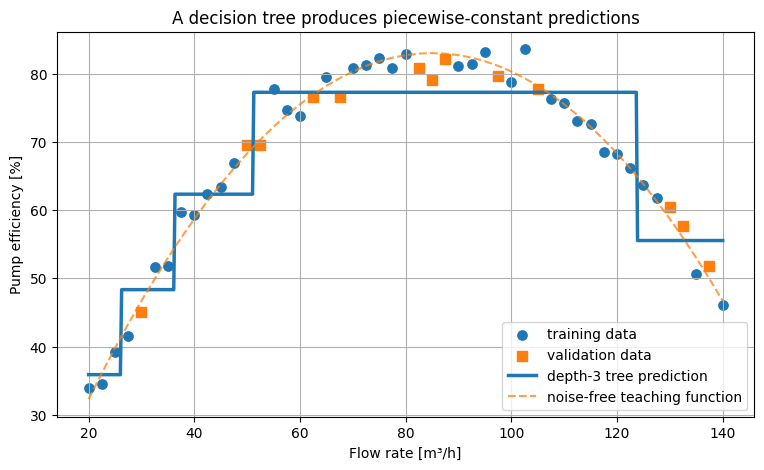

In [ ]:
flow_grid = pd.DataFrame({
    "flow_rate_m3h": np.linspace(
        pump_data["flow_rate_m3h"].min(),
        pump_data["flow_rate_m3h"].max(),
        500,
    )
})
tree_grid_prediction = pump_tree.predict(flow_grid)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    X_train["flow_rate_m3h"],
    y_train,
    s=45,
    label="training data",
)
ax.scatter(
    X_validation["flow_rate_m3h"],
    y_validation,
    marker="s",
    s=55,
    label="validation data",
)
ax.plot(
    flow_grid["flow_rate_m3h"],
    tree_grid_prediction,
    linewidth=2.5,
    label="depth-3 tree prediction",
)
ax.plot(
    pump_data["flow_rate_m3h"],
    pump_data["true_efficiency_for_teaching_only"],
    "--",
    alpha=0.75,
    label="noise-free teaching function",
)

ax.set_xlabel("Flow rate [m³/h]")
ax.set_ylabel("Pump efficiency [%]")
ax.set_title("A decision tree produces piecewise-constant predictions")
ax.grid(True)
ax.legend()

plt.show()


### 🧠 What should you notice?

The prediction changes only at learned split thresholds. Every query inside one
leaf receives the same predicted efficiency.

A deeper tree creates more and narrower steps. This may approximate the training
data more closely, but it can also reproduce measurement noise.


## 📂 5.2.5 Reading the fitted tree

The diagram below starts at the root node. Each internal node displays:

* the threshold rule;
* the squared-error impurity;
* the number of training samples; and
* the mean efficiency inside the node.

Follow the left branch when the rule is true and the right branch when it is
false.


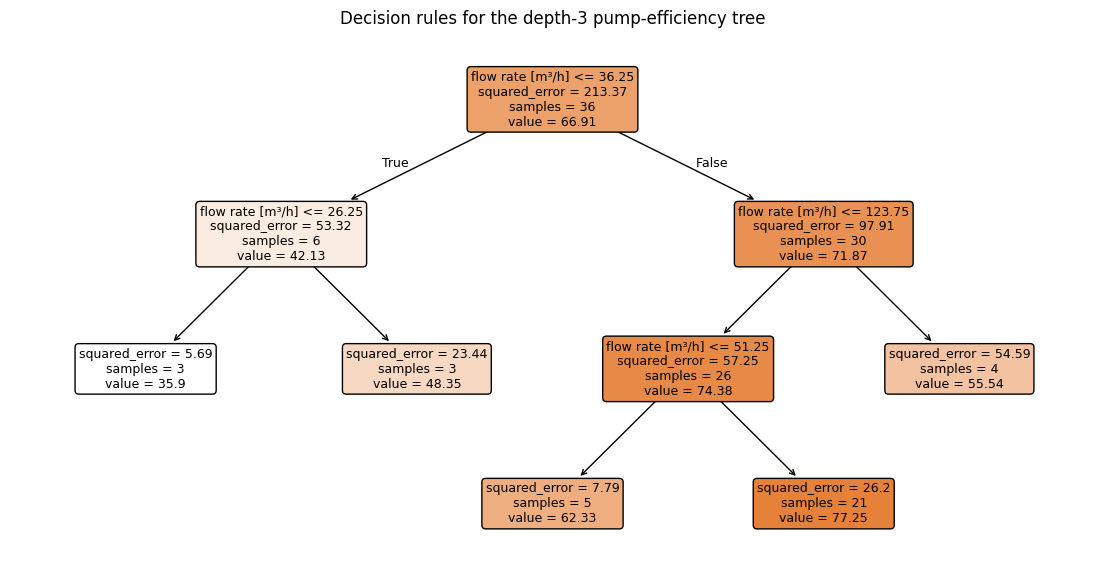

In [ ]:
fig, ax = plt.subplots(figsize=(14, 7))

plot_tree(
    pump_tree,
    feature_names=["flow rate [m³/h]"],
    filled=True,
    rounded=True,
    precision=2,
    fontsize=9,
    ax=ax,
)

ax.set_title("Decision rules for the depth-3 pump-efficiency tree")
plt.show()


In [ ]:
query_flow = pd.DataFrame({
    "flow_rate_m3h": [35.0, 65.0, 85.0, 105.0, 130.0]
})

query_results = query_flow.copy()
query_results["leaf_id"] = pump_tree.apply(query_flow)
query_results["predicted_efficiency_percent"] = pump_tree.predict(query_flow)

query_results


,flow_rate_m3h,leaf_id,predicted_efficiency_percent
0,35.0,3,48.3512
1,65.0,7,77.2530
2,85.0,7,77.2530
3,105.0,7,77.2530
4,130.0,8,55.5428


### 🧩 Interpretation

Two query points that reach the same leaf receive the same prediction, even when
their flow rates differ. The `leaf_id` identifies the terminal region; it is an
internal model identifier, not an engineering category.


## 📂 5.2.6 Underfitting and overfitting

Tree depth controls how many sequential rules can be used.

* A very shallow tree may **underfit** by merging distinct operating regions.
* A very deep tree may **overfit** by creating small leaves around measurement
  noise.

The plots below compare a depth-1 tree, a depth-3 tree and an unrestricted tree.


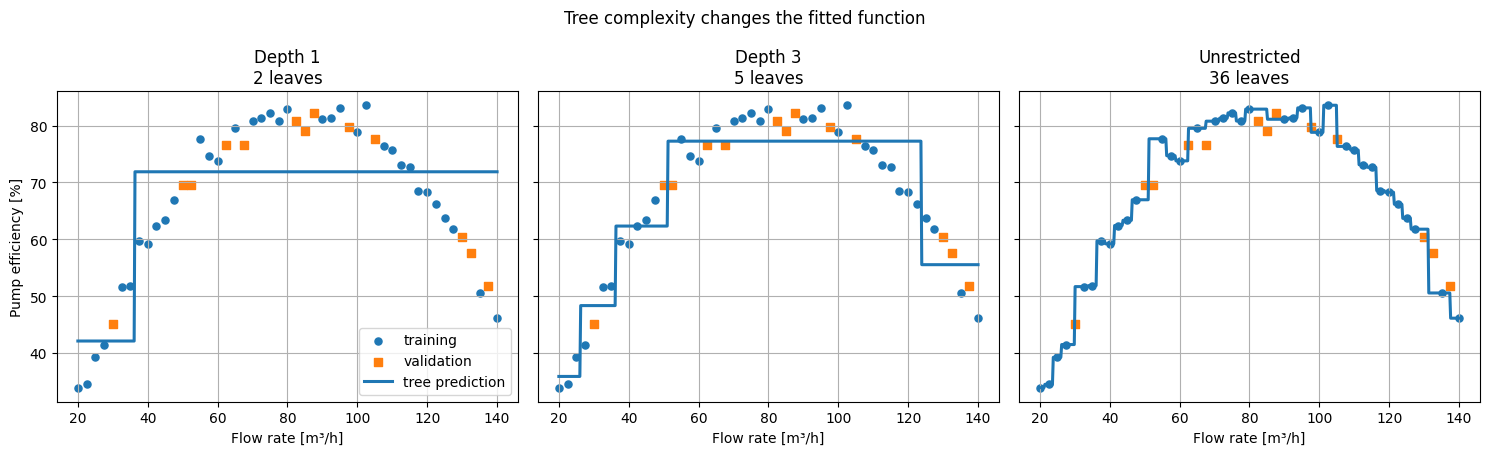

In [ ]:
complexity_models = {
    "Depth 1": DecisionTreeRegressor(
        max_depth=1,
        random_state=42,
    ),
    "Depth 3": DecisionTreeRegressor(
        max_depth=3,
        min_samples_leaf=3,
        random_state=42,
    ),
    "Unrestricted": DecisionTreeRegressor(
        random_state=42,
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)

for ax, (label, model) in zip(axes, complexity_models.items()):
    model.fit(X_train, y_train)
    ax.scatter(X_train["flow_rate_m3h"], y_train, s=26, label="training")
    ax.scatter(
        X_validation["flow_rate_m3h"],
        y_validation,
        marker="s",
        s=34,
        label="validation",
    )
    ax.plot(
        flow_grid["flow_rate_m3h"],
        model.predict(flow_grid),
        linewidth=2.2,
        label="tree prediction",
    )
    ax.set_title(
        f"{label}\n{model.get_n_leaves()} leaves"
    )
    ax.set_xlabel("Flow rate [m³/h]")
    ax.grid(True)

axes[0].set_ylabel("Pump efficiency [%]")
axes[0].legend()
fig.suptitle("Tree complexity changes the fitted function")
fig.tight_layout()

plt.show()


### 🧠 What should you notice?

The depth-1 tree is too coarse to represent the efficiency curve. The unrestricted
tree follows nearly every training observation and creates many narrow steps.

A moderate tree deliberately leaves some training error. That can improve
prediction on unseen data.


## 📂 5.2.7 Training error versus validation error

We now fit trees across a range of maximum depths. Training RMSE should normally
decrease as the tree becomes more flexible. Validation RMSE may decrease at first
and then rise when the model begins fitting noise.


In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


depth_records = []

for requested_depth in range(1, 13):
    model = DecisionTreeRegressor(
        max_depth=requested_depth,
        random_state=42,
    )
    model.fit(X_train, y_train)

    depth_records.append({
        "requested_max_depth": requested_depth,
        "fitted_depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "training_RMSE_percent": rmse(y_train, model.predict(X_train)),
        "validation_RMSE_percent": rmse(
            y_validation,
            model.predict(X_validation),
        ),
    })

depth_results = pd.DataFrame(depth_records)
depth_results


,requested_max_depth,fitted_depth,leaves,training_RMSE_percent,validation_RMSE_percent
0,1,1,2,9.5121,9.3348
1,2,2,4,6.9671,4.9868
2,3,3,8,4.0942,4.6879
3,4,4,14,2.3122,4.1773
4,5,5,18,1.5199,3.2762
5,6,6,23,0.7865,3.8447
6,7,7,27,0.6761,4.0357
7,8,8,28,0.5320,4.0769
8,9,9,29,0.4010,4.0050
9,10,10,31,0.2929,4.0210


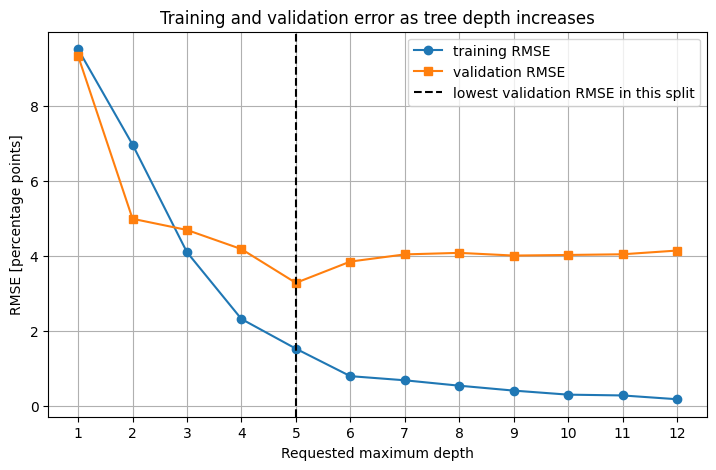

,value
requested_max_depth,5.0000
fitted_depth,5.0000
leaves,18.0000
training_RMSE_percent,1.5199
validation_RMSE_percent,3.2762


In [ ]:
best_depth_row = depth_results.loc[
    depth_results["validation_RMSE_percent"].idxmin()
]

fig, ax = plt.subplots(figsize=(8.5, 5))

ax.plot(
    depth_results["requested_max_depth"],
    depth_results["training_RMSE_percent"],
    "o-",
    label="training RMSE",
)
ax.plot(
    depth_results["requested_max_depth"],
    depth_results["validation_RMSE_percent"],
    "s-",
    label="validation RMSE",
)
ax.axvline(
    best_depth_row["requested_max_depth"],
    color="black",
    linestyle="--",
    label="lowest validation RMSE in this split",
)

ax.set_xlabel("Requested maximum depth")
ax.set_ylabel("RMSE [percentage points]")
ax.set_title("Training and validation error as tree depth increases")
ax.set_xticks(depth_results["requested_max_depth"])
ax.grid(True)
ax.legend()

plt.show()

best_depth_row.to_frame(name="value")


### ⚠️ Engineering warning

The depth with the lowest error in one small validation split is not a universal
optimum. It can change when:

* the split changes;
* more data is collected;
* the operating domain changes; or
* a different error metric is used.

Week 5.5 will develop more reliable evaluation using repeated or cross-validation
approaches where appropriate.


## 📂 5.2.8 Minimum leaf size

`min_samples_leaf` prevents a leaf from being supported by too few training
samples. Increasing it usually smooths the tree by removing narrow regions.

This is often easier to explain physically than allowing isolated measurements to
define their own operating regions.


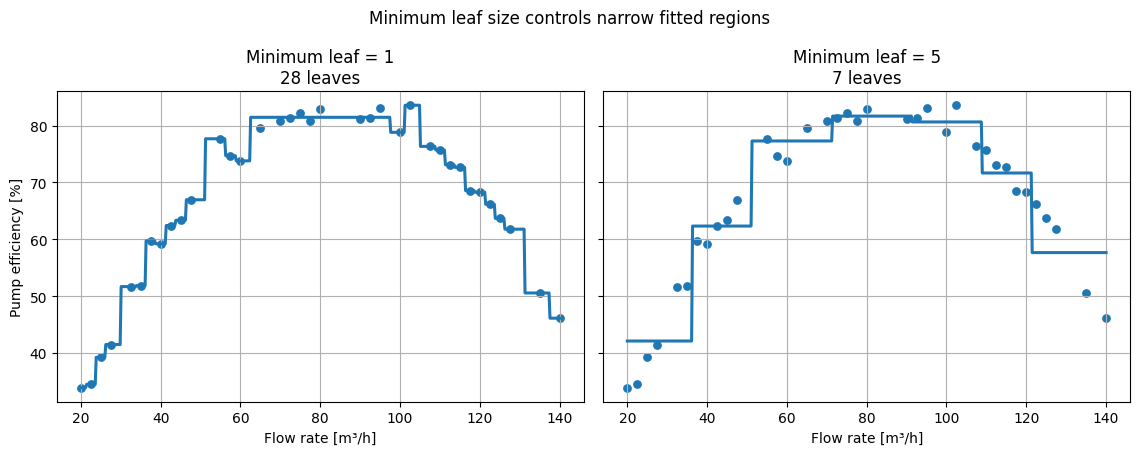

,model,fitted_depth,leaves,validation_RMSE_percent
0,Minimum leaf = 1,8,28,4.0769
1,Minimum leaf = 5,6,7,3.7303


In [ ]:
leaf_models = {
    "Minimum leaf = 1": DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=1,
        random_state=42,
    ),
    "Minimum leaf = 5": DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
    ),
}

leaf_metric_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)

for ax, (label, model) in zip(axes, leaf_models.items()):
    model.fit(X_train, y_train)
    validation_prediction = model.predict(X_validation)

    leaf_metric_rows.append({
        "model": label,
        "fitted_depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "validation_RMSE_percent": rmse(
            y_validation,
            validation_prediction,
        ),
    })

    ax.scatter(X_train["flow_rate_m3h"], y_train, s=28)
    ax.plot(
        flow_grid["flow_rate_m3h"],
        model.predict(flow_grid),
        linewidth=2.2,
    )
    ax.set_title(f"{label}\n{model.get_n_leaves()} leaves")
    ax.set_xlabel("Flow rate [m³/h]")
    ax.grid(True)

axes[0].set_ylabel("Pump efficiency [%]")
fig.suptitle("Minimum leaf size controls narrow fitted regions")
fig.tight_layout()
plt.show()

pd.DataFrame(leaf_metric_rows)


## 📂 5.2.9 Extrapolation behaviour

A decision tree predicts using the leaf reached by a query. Outside the observed
flow range, there are no new splits and no learned physical trend. The prediction
therefore remains at the value of a boundary leaf.

This is a critical difference from models that extend an equation beyond the data
range. Neither behaviour is automatically trustworthy.


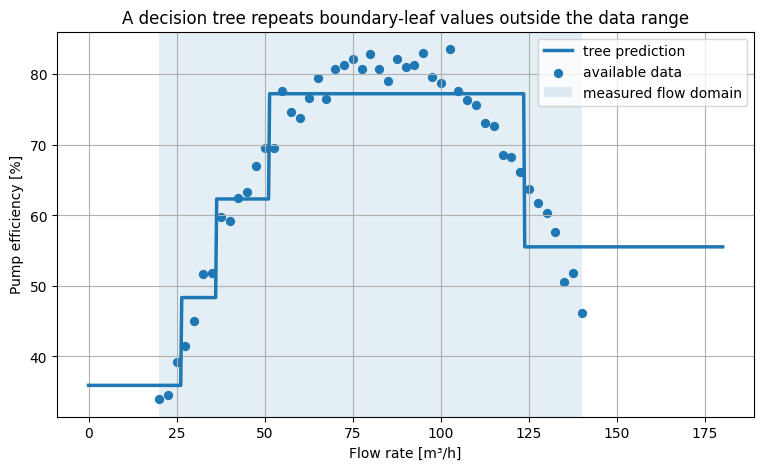

In [ ]:
extended_flow_grid = pd.DataFrame({
    "flow_rate_m3h": np.linspace(0.0, 180.0, 600)
})

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    extended_flow_grid["flow_rate_m3h"],
    pump_tree.predict(extended_flow_grid),
    linewidth=2.5,
    label="tree prediction",
)
ax.scatter(
    pump_data["flow_rate_m3h"],
    pump_data["efficiency_percent"],
    s=32,
    label="available data",
)
ax.axvspan(
    pump_data["flow_rate_m3h"].min(),
    pump_data["flow_rate_m3h"].max(),
    alpha=0.12,
    label="measured flow domain",
)

ax.set_xlabel("Flow rate [m³/h]")
ax.set_ylabel("Pump efficiency [%]")
ax.set_title("A decision tree repeats boundary-leaf values outside the data range")
ax.grid(True)
ax.legend()

plt.show()


In [ ]:
def predict_efficiency_with_support_check(model, flow_m3h, training_flow_m3h):
    query = np.atleast_1d(flow_m3h).astype(float)
    training = np.asarray(training_flow_m3h, dtype=float)

    query_frame = pd.DataFrame({"flow_rate_m3h": query})
    inside = (query >= training.min()) & (query <= training.max())

    return pd.DataFrame({
        "flow_rate_m3h": query,
        "predicted_efficiency_percent": model.predict(query_frame),
        "support": np.where(
            inside,
            "inside measured range",
            "outside measured range",
        ),
    })


predict_efficiency_with_support_check(
    pump_tree,
    [10.0, 60.0, 100.0, 165.0],
    X_train["flow_rate_m3h"],
)


,flow_rate_m3h,predicted_efficiency_percent,support
0,10.0,35.9002,outside measured range
1,60.0,77.2530,inside measured range
2,100.0,77.2530,inside measured range
3,165.0,55.5428,outside measured range


## 📂 5.2.10 Optional interactive depth demonstration

Run the cell below. If `ipywidgets` is available, move the slider to see how depth
changes the number of leaves and the prediction curve. No code editing is required.
A static depth-4 demonstration is shown if widgets are unavailable.


In [ ]:
def plot_tree_depth_effect(max_depth=3):
    demo_tree = DecisionTreeRegressor(
        max_depth=max_depth,
        random_state=42,
    )
    demo_tree.fit(X_train, y_train)

    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.scatter(X_train["flow_rate_m3h"], y_train, s=32, label="training")
    ax.scatter(
        X_validation["flow_rate_m3h"],
        y_validation,
        marker="s",
        s=40,
        label="validation",
    )
    ax.plot(
        flow_grid["flow_rate_m3h"],
        demo_tree.predict(flow_grid),
        linewidth=2.3,
        label="tree prediction",
    )
    ax.set_xlabel("Flow rate [m³/h]")
    ax.set_ylabel("Pump efficiency [%]")
    ax.set_title(
        f"Maximum depth = {max_depth}; "
        f"leaves = {demo_tree.get_n_leaves()}"
    )
    ax.grid(True)
    ax.legend()
    plt.show()


try:
    from ipywidgets import IntSlider, interact

    interact(
        plot_tree_depth_effect,
        max_depth=IntSlider(
            value=3,
            min=1,
            max=10,
            step=1,
            description="max depth",
            continuous_update=False,
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the static depth-4 scenario.")
    plot_tree_depth_effect(max_depth=4)


interactive(children=(IntSlider(value=3, continuous_update=False, description='max depth', max=10, min=1), Out…

## 📂 5.2.11 Two-feature tree: flow rate and rotational speed

Pump behaviour also changes with rotational speed. We will now create a synthetic
dataset with two features:

* flow rate in cubic metres per hour; and
* rotational speed in revolutions per minute.

The tree will partition a two-dimensional feature space using axis-aligned rules.


In [ ]:
rng = np.random.default_rng(5202)
n_samples = 260

flow_2d_m3h = rng.uniform(25.0, 155.0, n_samples)
speed_rpm = rng.uniform(1200.0, 2200.0, n_samples)

speed_ratio = speed_rpm / 1800.0
best_flow_for_speed = 85.0 * speed_ratio

true_efficiency_2d = np.clip(
    83.0
    - 0.0105 * (flow_2d_m3h - best_flow_for_speed) ** 2
    - 0.000004 * (speed_rpm - 1800.0) ** 2,
    10.0,
    85.0,
)
measured_efficiency_2d = np.clip(
    true_efficiency_2d
    + rng.normal(0.0, 1.5, n_samples),
    5.0,
    90.0,
)

pump_2d_data = pd.DataFrame({
    "flow_rate_m3h": flow_2d_m3h,
    "speed_rpm": speed_rpm,
    "efficiency_percent": measured_efficiency_2d,
})

pump_2d_data.head()


,flow_rate_m3h,speed_rpm,efficiency_percent
0,127.1036,1267.1538,33.0453
1,153.4243,2000.7446,45.6706
2,72.3282,1248.9825,80.4128
3,132.6478,1943.1071,67.0185
4,33.3345,1286.6568,77.0249


In [ ]:
X_2d = pump_2d_data[["flow_rate_m3h", "speed_rpm"]]
y_2d = pump_2d_data["efficiency_percent"]

X2_train, X2_validation, y2_train, y2_validation = train_test_split(
    X_2d,
    y_2d,
    test_size=0.25,
    random_state=42,
)

pump_tree_2d = DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=6,
    random_state=42,
)
pump_tree_2d.fit(X2_train, y2_train)

prediction_2d_validation = pump_tree_2d.predict(X2_validation)

performance_2d = pd.DataFrame({
    "metric": ["MAE", "RMSE", "R2"],
    "validation_value": [
        mean_absolute_error(y2_validation, prediction_2d_validation),
        rmse(y2_validation, prediction_2d_validation),
        r2_score(y2_validation, prediction_2d_validation),
    ],
    "units": ["percentage points", "percentage points", "dimensionless"],
})

performance_2d


,metric,validation_value,units
0,MAE,5.3242,percentage points
1,RMSE,7.0379,percentage points
2,R2,0.8860,dimensionless


## 📂 5.2.12 Visualising a two-feature tree

The left figure shows the noise-free teaching relationship. The right figure shows
the tree prediction. Block-like regions reveal the tree's axis-aligned partitions.

Real engineering data would not provide the left-hand truth surface; it is included
here only because the dataset is synthetic.


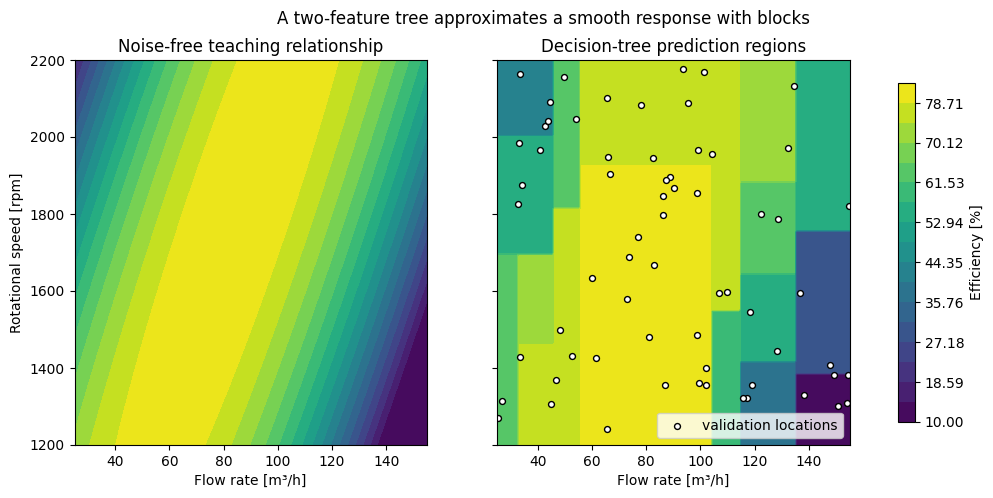

In [ ]:
flow_axis_2d = np.linspace(25.0, 155.0, 160)
speed_axis_2d = np.linspace(1200.0, 2200.0, 160)
flow_surface_2d, speed_surface_2d = np.meshgrid(
    flow_axis_2d,
    speed_axis_2d,
)

speed_ratio_surface = speed_surface_2d / 1800.0
best_flow_surface = 85.0 * speed_ratio_surface
true_surface_2d = np.clip(
    83.0
    - 0.0105 * (flow_surface_2d - best_flow_surface) ** 2
    - 0.000004 * (speed_surface_2d - 1800.0) ** 2,
    10.0,
    85.0,
)

surface_queries_2d = pd.DataFrame({
    "flow_rate_m3h": flow_surface_2d.ravel(),
    "speed_rpm": speed_surface_2d.ravel(),
})
tree_surface_2d = pump_tree_2d.predict(surface_queries_2d).reshape(
    flow_surface_2d.shape
)

colour_min = min(true_surface_2d.min(), tree_surface_2d.min())
colour_max = max(true_surface_2d.max(), tree_surface_2d.max())
levels = np.linspace(colour_min, colour_max, 18)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), sharex=True, sharey=True)

left = axes[0].contourf(
    flow_surface_2d,
    speed_surface_2d,
    true_surface_2d,
    levels=levels,
    cmap="viridis",
)
axes[0].set_title("Noise-free teaching relationship")

right = axes[1].contourf(
    flow_surface_2d,
    speed_surface_2d,
    tree_surface_2d,
    levels=levels,
    cmap="viridis",
)
axes[1].scatter(
    X2_validation["flow_rate_m3h"],
    X2_validation["speed_rpm"],
    c="white",
    edgecolor="black",
    s=18,
    label="validation locations",
)
axes[1].set_title("Decision-tree prediction regions")
axes[1].legend(loc="lower right")

for ax in axes:
    ax.set_xlabel("Flow rate [m³/h]")
    ax.grid(False)

axes[0].set_ylabel("Rotational speed [rpm]")
fig.colorbar(
    right,
    ax=axes,
    shrink=0.88,
    label="Efficiency [%]",
)
fig.suptitle("A two-feature tree approximates a smooth response with blocks")

plt.show()


### 🧠 What should you notice?

The true teaching relationship changes smoothly. The decision tree approximates it
using rectangular regions with constant predictions.

Trees generally do not require feature scaling because threshold splits depend on
feature ordering rather than Euclidean distance. However, their axis-aligned
partitions can be inefficient when the important relationship is diagonal or
rotated in feature space.


## 📂 5.2.13 Which feature does the fitted model rely on?

Permutation importance measures how much validation performance decreases when one
feature is shuffled. Shuffling breaks that feature's relationship with the target
while leaving the fitted tree unchanged.

We compute importance on validation data because our interest is the model's
generalisation behaviour, not merely its fit to training data.


In [ ]:
importance_result = permutation_importance(
    pump_tree_2d,
    X2_validation,
    y2_validation,
    scoring="neg_root_mean_squared_error",
    n_repeats=30,
    random_state=42,
)

importance_table = pd.DataFrame({
    "feature": X2_validation.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std,
}).sort_values("importance_mean", ascending=False)

importance_table


,feature,importance_mean,importance_std
0,flow_rate_m3h,18.8574,1.7242
1,speed_rpm,7.7584,1.2614


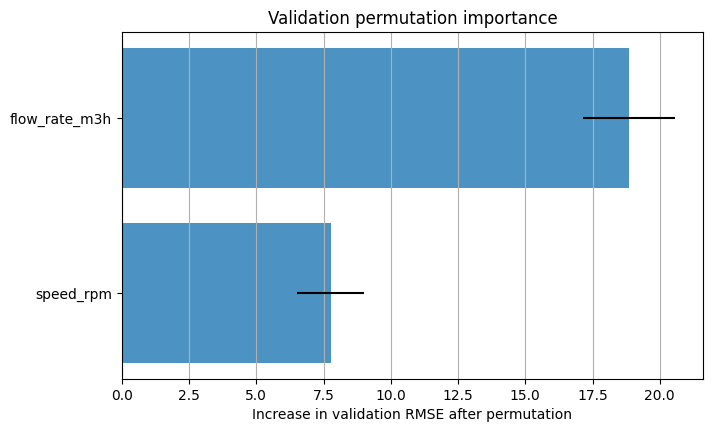

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.barh(
    importance_table["feature"],
    importance_table["importance_mean"],
    xerr=importance_table["importance_std"],
    alpha=0.8,
)
ax.invert_yaxis()
ax.set_xlabel("Increase in validation RMSE after permutation")
ax.set_title("Validation permutation importance")
ax.grid(True, axis="x")

plt.show()


### ⚠️ Interpretation warning

Feature importance describes this fitted model on this dataset using this metric.
It does not prove causality.

Importance can also be misleading when features are strongly correlated: the model
may substitute one feature for another, reducing the apparent importance of both.
Evaluate model performance before interpreting importance values.


## 📂 5.2.14 Method limitations and engineering checks

Before using a decision tree regressor, ask:

1. Is the target continuous and meaningful?
2. Do threshold-like local regions suit the engineering task?
3. Was complexity selected using validation evidence?
4. Are leaves supported by enough relevant samples?
5. Are the stepwise predictions acceptable for the application?
6. Are queries inside the supported feature domain?
7. Could small data changes produce very different rules?
8. Are feature-importance claims limited to model reliance rather than causality?
9. Does the tree outperform a simple baseline?
10. Is prediction error acceptable for the engineering consequence?

A single tree is interpretable when small, but can become unstable and difficult to
generalise when grown deeply.


## 📂 5.2.15 Useful packages and functions

| Package | Function or attribute | Purpose | Important output or caution |
|---|---|---|---|
| `sklearn.tree` | `DecisionTreeRegressor` | Fit a regression tree | Uncontrolled defaults can overfit |
| estimator parameter | `max_depth` | Limit rule depth | Smaller values reduce flexibility |
| estimator parameter | `min_samples_leaf` | Require support in each leaf | Larger values remove narrow regions |
| fitted estimator | `get_depth()` | Report fitted depth | May be lower than requested maximum |
| fitted estimator | `get_n_leaves()` | Report terminal regions | More leaves usually mean more complexity |
| fitted estimator | `apply()` | Return leaf IDs for queries | IDs are internal, not physical classes |
| `sklearn.tree` | `plot_tree` | Visualise learned rules | Best suited to small trees |
| `sklearn.inspection` | `permutation_importance` | Measure validation-score reliance on features | Depends on model, data and metric |


## 📂 5.2.16 Engineering workflow and summary

A defensible tree-regression workflow is:

1. define the prediction task, units and operating domain;
2. inspect the data and choose an appropriate validation strategy;
3. fit a small tree first;
4. connect the tree diagram to prediction regions;
5. compare training and validation error as complexity changes;
6. require adequate sample support in each leaf;
7. check stepwise and out-of-range behaviour;
8. inspect multidimensional prediction regions;
9. interpret feature reliance cautiously; and
10. communicate assumptions, limitations and intended use.

Decision trees are flexible and visually explainable, but they trade smoothness and
stable extrapolation for threshold-based local rules.


## 📚 References

* scikit-learn developers, *DecisionTreeRegressor*, stable documentation.
* scikit-learn developers, *Decision Trees User Guide*, stable documentation.
* scikit-learn developers, *Permutation Feature Importance*, stable documentation.
* US Department of Energy, *Improving Pumping System Performance: A Sourcebook for
  Industry*.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop teaching examples
and review code. The teaching team remains responsible for the mathematical
content, engineering interpretation, source selection and final notebook.
